#Import

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import scipy as sp
%matplotlib inline

In [ ]:
plt.style.use('ggplot')

In [ ]:
df = pd.read_csv("/content/SuperStoreOrders.csv")

In [ ]:
pd.set_option('display.max_columns', None)

In [ ]:
df.head(5)

,order_id,order_date,ship_date,ship_mode,customer_name,segment,state,country,market,region,product_id,category,sub_category,product_name,sales,quantity,discount,profit,shipping_cost,order_priority,year
0,AG-2011-2040,1/1/2011,6/1/2011,Standard Class,Toby Braunhardt,Consumer,Constantine,Algeria,Africa,Africa,OFF-TEN-10000025,Office Supplies,Storage,"Tenex Lockers, Blue",408,2,0.0,106.140,35.46,Medium,2011
1,IN-2011-47883,1/1/2011,8/1/2011,Standard Class,Joseph Holt,Consumer,New South Wales,Australia,APAC,Oceania,OFF-SU-10000618,Office Supplies,Supplies,"Acme Trimmer, High Speed",120,3,0.1,36.036,9.72,Medium,2011
2,HU-2011-1220,1/1/2011,5/1/2011,Second Class,Annie Thurman,Consumer,Budapest,Hungary,EMEA,EMEA,OFF-TEN-10001585,Office Supplies,Storage,"Tenex Box, Single Width",66,4,0.0,29.640,8.17,High,2011
3,IT-2011-3647632,1/1/2011,5/1/2011,Second Class,Eugene Moren,Home Office,Stockholm,Sweden,EU,North,OFF-PA-10001492,Office Supplies,Paper,"Enermax Note Cards, Premium",45,3,0.5,-26.055,4.82,High,2011
4,IN-2011-47883,1/1/2011,8/1/2011,Standard Class,Joseph Holt,Consumer,New South Wales,Australia,APAC,Oceania,FUR-FU-10003447,Furniture,Furnishings,"Eldon Light Bulb, Duo Pack",114,5,0.1,37.770,4.70,Medium,2011


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 51290 entries, 0 to 51289
Data columns (total 21 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   order_id        51290 non-null  object 
 1   order_date      51290 non-null  object 
 2   ship_date       51290 non-null  object 
 3   ship_mode       51290 non-null  object 
 4   customer_name   51290 non-null  object 
 5   segment         51290 non-null  object 
 6   state           51290 non-null  object 
 7   country         51290 non-null  object 
 8   market          51290 non-null  object 
 9   region          51290 non-null  object 
 10  product_id      51290 non-null  object 
 11  category        51290 non-null  object 
 12  sub_category    51290 non-null  object 
 13  product_name    51290 non-null  object 
 14  sales           51290 non-null  object 
 15  quantity        51290 non-null  int64  
 16  discount        51290 non-null  float64
 17  profit          51290 non-null 

In [ ]:
df.isnull().sum()

,0
order_id,0
order_date,0
ship_date,0
ship_mode,0
customer_name,0
segment,0
state,0
country,0
market,0
region,0


In [ ]:
print(df[['sales', 'profit']].describe())

             profit
count  51290.000000
mean      28.641740
std      174.424113
min    -6599.978000
25%        0.000000
50%        9.240000
75%       36.810000
max     8399.976000


In [ ]:
df.describe()

,order_date,ship_date,sales,quantity,discount,profit,shipping_cost,year,shipping_days,month
count,20067,19834,51290.000000,51290.000000,51290.000000,51290.000000,51290.000000,51290.000000,13297.000000,20067.000000
mean,2013-04-04 09:40:45.029152256,2013-04-14 00:24:19.312292096,246.498440,3.476545,0.142908,28.641740,26.375915,2012.777208,108.870196,6.569991
min,2011-01-01 00:00:00,2011-01-02 00:00:00,0.000000,1.000000,0.000000,-6599.978000,0.000000,2011.000000,0.000000,1.000000
25%,2012-05-04 00:00:00,2012-05-09 00:00:00,31.000000,2.000000,0.000000,0.000000,2.610000,2012.000000,61.000000,4.000000
50%,2013-06-04 00:00:00,2013-06-05 00:00:00,85.000000,3.000000,0.000000,9.240000,7.790000,2013.000000,122.000000,7.000000
75%,2014-04-06 00:00:00,2014-04-08 00:00:00,251.000000,5.000000,0.200000,36.810000,24.450000,2014.000000,153.000000,10.000000
max,2014-12-12 00:00:00,2015-07-01 00:00:00,22638.000000,14.000000,0.850000,8399.976000,933.570000,2014.000000,214.000000,12.000000
std,NaN,NaN,487.567175,2.278766,0.212280,174.424113,57.296804,1.098931,53.365323,3.448128


#Cleansing

## Mising Value

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 51290 entries, 0 to 51289
Data columns (total 21 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   order_id        51290 non-null  object 
 1   order_date      51290 non-null  object 
 2   ship_date       51290 non-null  object 
 3   ship_mode       51290 non-null  object 
 4   customer_name   51290 non-null  object 
 5   segment         51290 non-null  object 
 6   state           51290 non-null  object 
 7   country         51290 non-null  object 
 8   market          51290 non-null  object 
 9   region          51290 non-null  object 
 10  product_id      51290 non-null  object 
 11  category        51290 non-null  object 
 12  sub_category    51290 non-null  object 
 13  product_name    51290 non-null  object 
 14  sales           51290 non-null  object 
 15  quantity        51290 non-null  int64  
 16  discount        51290 non-null  float64
 17  profit          51290 non-null 

In [ ]:
(df.isna().sum()/df.shape[0])*100

,0
order_id,0.0
order_date,0.0
ship_date,0.0
ship_mode,0.0
customer_name,0.0
segment,0.0
state,0.0
country,0.0
market,0.0
region,0.0


## Duplikat

In [ ]:
duplicate_count = df.duplicated().sum()

print("Jumlah data duplikat:", duplicate_count)

Jumlah data duplikat: 0


## Type Data

In [ ]:
#Date
df['order_date'] = pd.to_datetime(df['order_date'], errors='coerce')
df['ship_date'] = pd.to_datetime(df['ship_date'], errors='coerce')

In [ ]:
#Numeric
df['sales'] = pd.to_numeric(
    df['sales'].astype(str).str.replace(',', ''),
    errors='coerce'
)
df["sales"] = df["sales"].astype(float)
df['quantity'] = pd.to_numeric(df['quantity'],errors='coerce')
df['discount'] = pd.to_numeric(df['discount'],errors='coerce')
df['profit'] = pd.to_numeric(df['profit'],errors='coerce')
df['shipping_cost'] = pd.to_numeric(df['shipping_cost'],errors='coerce')

In [ ]:
# ship_date tidak boleh sebelum order_date
df[df["ship_date"] < df["order_date"]]

,order_id,order_date,ship_date,ship_mode,customer_name,segment,state,country,market,region,product_id,category,sub_category,product_name,sales,quantity,discount,profit,shipping_cost,order_priority,year


## Cek Nilai Negatif

In [ ]:
negative_sales = df[df['sales'] < 0]
print(negative_sales)
print("Jumlah Sales negatif:", len(negative_sales))

Empty DataFrame
Columns: [order_id, order_date, ship_date, ship_mode, customer_name, segment, state, country, market, region, product_id, category, sub_category, product_name, sales, quantity, discount, profit, shipping_cost, order_priority, year]
Index: []
Jumlah Sales negatif: 0


In [ ]:
negative_quantity = df[df['quantity'] <= 0]
print(negative_quantity)
print("Jumlah Quantity <= 0:", len(negative_quantity))

Empty DataFrame
Columns: [order_id, order_date, ship_date, ship_mode, customer_name, segment, state, country, market, region, product_id, category, sub_category, product_name, sales, quantity, discount, profit, shipping_cost, order_priority, year]
Index: []
Jumlah Quantity <= 0: 0


In [ ]:
negative_shipping = df[df['shipping_cost'] < 0]
print(negative_shipping)
print("Jumlah Shipping Cost negatif:", len(negative_shipping))

Empty DataFrame
Columns: [order_id, order_date, ship_date, ship_mode, customer_name, segment, state, country, market, region, product_id, category, sub_category, product_name, sales, quantity, discount, profit, shipping_cost, order_priority, year]
Index: []
Jumlah Shipping Cost negatif: 0


In [ ]:
negative_discount = df[df['discount'] < 0]
print(negative_discount)
print("Jumlah Discount negatif:", len(negative_discount))

Empty DataFrame
Columns: [order_id, order_date, ship_date, ship_mode, customer_name, segment, state, country, market, region, product_id, category, sub_category, product_name, sales, quantity, discount, profit, shipping_cost, order_priority, year]
Index: []
Jumlah Discount negatif: 0


In [ ]:
df[df['discount'] > 1]

,order_id,order_date,ship_date,ship_mode,customer_name,segment,state,country,market,region,product_id,category,sub_category,product_name,sales,quantity,discount,profit,shipping_cost,order_priority,year


In [ ]:
df[df['discount'] > 100]

,order_id,order_date,ship_date,ship_mode,customer_name,segment,state,country,market,region,product_id,category,sub_category,product_name,sales,quantity,discount,profit,shipping_cost,order_priority,year


In [ ]:
numeric_cols = df.select_dtypes(include=['int64', 'float64']).columns

for col in numeric_cols:
    negative = (df[col] < 0).sum()
    print(f"{col}: {negative}")

sales: 0
quantity: 0
discount: 0
profit: 12543
shipping_cost: 0
year: 0


## Outlier

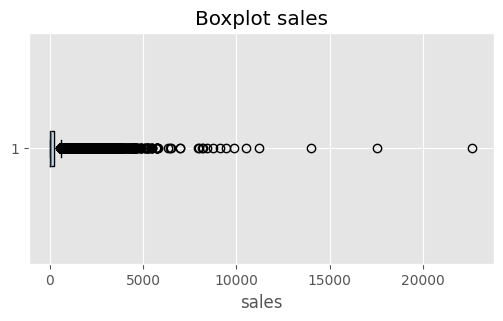

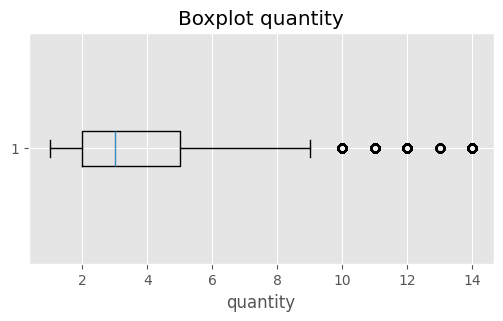

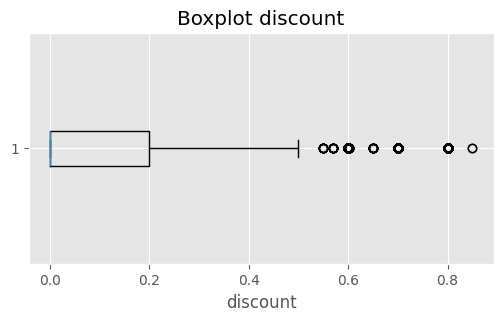

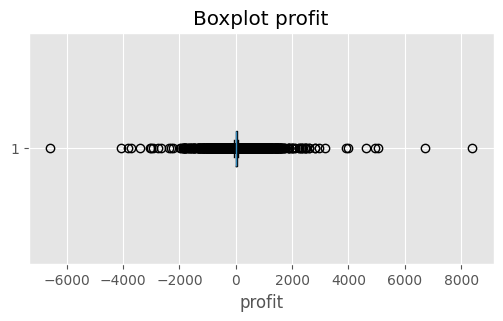

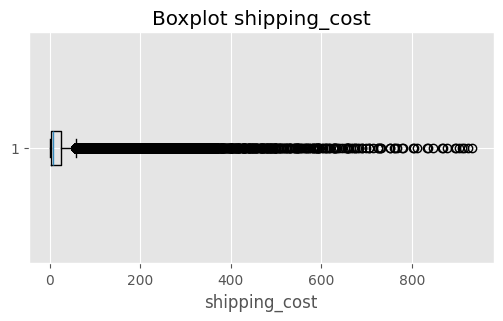

In [ ]:
numeric_cols = ['sales', 'quantity', 'discount', 'profit', 'shipping_cost']

for col in numeric_cols:
    plt.figure(figsize=(6,3))
    plt.boxplot(df[col], vert=False)
    plt.title(f'Boxplot {col}')
    plt.xlabel(col)
    plt.show()

In [ ]:
numeric_cols = ['sales', 'quantity', 'discount', 'profit', 'shipping_cost']

for col in numeric_cols:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)

    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    outlier = df[(df[col] < lower) | (df[col] > upper)]

    print(f"{col}")
    print(f"Jumlah Outlier : {len(outlier)}")
    print(f"Batas bawah : {lower}")
    print(f"Batas atas : {upper}")
    print("-"*50)

sales
Jumlah Outlier : 5655
Batas bawah : -299.0
Batas atas : 581.0
--------------------------------------------------
quantity
Jumlah Outlier : 877
Batas bawah : -2.5
Batas atas : 9.5
--------------------------------------------------
discount
Jumlah Outlier : 4172
Batas bawah : -0.30000000000000004
Batas atas : 0.5
--------------------------------------------------
profit
Jumlah Outlier : 9755
Batas bawah : -55.215
Batas atas : 92.025
--------------------------------------------------
shipping_cost
Jumlah Outlier : 5909
Batas bawah : -30.15
Batas atas : 57.209999999999994
--------------------------------------------------


In [ ]:
df.nlargest(10, 'sales')

,order_id,order_date,ship_date,ship_mode,customer_name,segment,state,country,market,region,product_id,category,sub_category,product_name,sales,quantity,discount,profit,shipping_cost,order_priority,year
1103,CA-2011-145317,NaT,NaT,Standard Class,Sean Miller,Home Office,Florida,United States,US,South,TEC-MA-10002412,Technology,Machines,Cisco TelePresence System EX90 Videoconferenci...,22638.0,6,0.5,-1811.0784,24.29,Medium,2011
29530,CA-2013-118689,2013-03-10,2013-10-10,Standard Class,Tamara Chand,Corporate,Indiana,United States,US,Central,TEC-CO-10004722,Technology,Copiers,Canon imageCLASS 2200 Advanced Copier,17500.0,5,0.0,8399.9760,349.07,Medium,2013
36239,CA-2014-140151,NaT,NaT,First Class,Raymond Buch,Consumer,Washington,United States,US,West,TEC-CO-10004722,Technology,Copiers,Canon imageCLASS 2200 Advanced Copier,14000.0,4,0.0,6719.9808,20.00,Medium,2014
46525,CA-2014-127180,NaT,NaT,First Class,Tom Ashbrook,Home Office,New York,United States,US,East,TEC-CO-10004722,Technology,Copiers,Canon imageCLASS 2200 Advanced Copier,11200.0,4,0.2,3919.9888,45.98,High,2014
48097,CA-2014-166709,NaT,NaT,Standard Class,Hunter Lopez,Consumer,Delaware,United States,US,East,TEC-CO-10004722,Technology,Copiers,Canon imageCLASS 2200 Advanced Copier,10500.0,3,0.0,5039.9856,363.19,Medium,2014
33011,CA-2013-117121,NaT,NaT,Standard Class,Adrian Barton,Consumer,Michigan,United States,US,Central,OFF-BI-10000545,Office Supplies,Binders,GBC Ibimaster 500 Manual ProClick Binding System,9893.0,13,0.0,4946.3700,498.70,Medium,2013
5522,CA-2011-116904,NaT,NaT,Standard Class,Sanjit Chand,Consumer,Minnesota,United States,US,Central,OFF-BI-10001120,Office Supplies,Binders,Ibico EPK-21 Electric Binding System,9450.0,5,0.0,4630.4755,655.61,Medium,2011
22483,US-2013-107440,NaT,NaT,Standard Class,Bill Shonely,Corporate,New Jersey,United States,US,East,TEC-MA-10001047,Technology,Machines,"3D Systems Cube Printer, 2nd Generation, Magenta",9100.0,7,0.0,2365.9818,516.91,Medium,2013
20693,CA-2013-158841,2013-02-02,2013-04-02,Second Class,Sanjit Engle,Consumer,Virginia,United States,US,South,TEC-MA-10001127,Technology,Machines,HP Designjet T520 Inkjet Large Format Printer ...,8750.0,5,0.0,2799.9840,17.83,Critical,2013
23575,CA-2013-143714,NaT,NaT,Standard Class,Christopher Conant,Consumer,Pennsylvania,United States,US,East,TEC-CO-10004722,Technology,Copiers,Canon imageCLASS 2200 Advanced Copier,8400.0,4,0.4,1119.9968,498.08,Medium,2013


In [ ]:
df.nlargest(10, 'profit')

,order_id,order_date,ship_date,ship_mode,customer_name,segment,state,country,market,region,product_id,category,sub_category,product_name,sales,quantity,discount,profit,shipping_cost,order_priority,year
29530,CA-2013-118689,2013-03-10,2013-10-10,Standard Class,Tamara Chand,Corporate,Indiana,United States,US,Central,TEC-CO-10004722,Technology,Copiers,Canon imageCLASS 2200 Advanced Copier,17500.0,5,0.0,8399.9760,349.07,Medium,2013
36239,CA-2014-140151,NaT,NaT,First Class,Raymond Buch,Consumer,Washington,United States,US,West,TEC-CO-10004722,Technology,Copiers,Canon imageCLASS 2200 Advanced Copier,14000.0,4,0.0,6719.9808,20.00,Medium,2014
48097,CA-2014-166709,NaT,NaT,Standard Class,Hunter Lopez,Consumer,Delaware,United States,US,East,TEC-CO-10004722,Technology,Copiers,Canon imageCLASS 2200 Advanced Copier,10500.0,3,0.0,5039.9856,363.19,Medium,2014
33011,CA-2013-117121,NaT,NaT,Standard Class,Adrian Barton,Consumer,Michigan,United States,US,Central,OFF-BI-10000545,Office Supplies,Binders,GBC Ibimaster 500 Manual ProClick Binding System,9893.0,13,0.0,4946.3700,498.70,Medium,2013
5522,CA-2011-116904,NaT,NaT,Standard Class,Sanjit Chand,Consumer,Minnesota,United States,US,Central,OFF-BI-10001120,Office Supplies,Binders,Ibico EPK-21 Electric Binding System,9450.0,5,0.0,4630.4755,655.61,Medium,2011
43831,ES-2014-1651774,2014-08-09,NaT,Standard Class,Patrick Jones,Corporate,Tuscany,Italy,EU,South,OFF-AP-10004512,Office Supplies,Appliances,"Hoover Stove, Red",7959.0,14,0.0,3979.0800,778.32,Low,2014
46525,CA-2014-127180,NaT,NaT,First Class,Tom Ashbrook,Home Office,New York,United States,US,East,TEC-CO-10004722,Technology,Copiers,Canon imageCLASS 2200 Advanced Copier,11200.0,4,0.2,3919.9888,45.98,High,2014
10265,CA-2012-145352,NaT,NaT,Standard Class,Christopher Martinez,Consumer,Georgia,United States,US,South,OFF-BI-10003527,Office Supplies,Binders,Fellowes PB500 Electric Punch Plastic Comb Bin...,6355.0,5,0.0,3177.4750,581.12,Medium,2012
548,ID-2011-64599,2011-10-02,NaT,Standard Class,Carol Adams,Corporate,Shizuoka,Japan,APAC,North Asia,TEC-PH-10000303,Technology,Phones,"Samsung Smart Phone, VoIP",6999.0,11,0.0,2939.3100,413.80,Medium,2011
24420,IN-2013-50809,2013-12-06,NaT,Standard Class,Cynthia Arntzen,Consumer,Chhattisgarh,India,APAC,Central Asia,TEC-PH-10000169,Technology,Phones,"Apple Smart Phone, with Caller ID",5752.0,9,0.0,2817.9900,353.85,Medium,2013


In [ ]:
df.nlargest(10, 'shipping_cost')

,order_id,order_date,ship_date,ship_mode,customer_name,segment,state,country,market,region,product_id,category,sub_category,product_name,sales,quantity,discount,profit,shipping_cost,order_priority,year
13891,CA-2012-124891,NaT,NaT,Same Day,Rick Hansen,Consumer,New York,United States,US,East,TEC-AC-10003033,Technology,Accessories,Plantronics CS510 - Over-the-Head monaural Wir...,2310.0,7,0.0,762.1845,933.57,Critical,2012
20727,IN-2013-77878,2013-05-02,2013-07-02,Second Class,Justin Ritter,Corporate,New South Wales,Australia,APAC,Oceania,FUR-CH-10003950,Furniture,Chairs,"Novimex Executive Leather Armchair, Black",3709.0,9,0.1,1288.7650,923.63,Critical,2013
30040,IN-2013-71249,NaT,NaT,First Class,Craig Reiter,Consumer,Queensland,Australia,APAC,Oceania,TEC-PH-10004664,Technology,Phones,"Nokia Smart Phone, with Caller ID",5175.0,9,0.1,919.9710,915.49,Medium,2013
20543,ES-2013-1579342,NaT,NaT,First Class,Katherine Murray,Home Office,Berlin,Germany,EU,Central,TEC-PH-10004583,Technology,Phones,"Motorola Smart Phone, Cordless",2893.0,5,0.1,-96.5400,910.16,Medium,2013
30718,SG-2013-4320,2013-05-11,2013-06-11,Same Day,Rick Hansen,Consumer,Dakar,Senegal,Africa,Africa,TEC-SHA-10000501,Technology,Copiers,"Sharp Wireless Fax, High-Speed",2833.0,8,0.0,311.5200,903.04,Critical,2013
25300,IN-2013-42360,NaT,2013-01-07,Second Class,Jim Mitchum,Corporate,New South Wales,Australia,APAC,Oceania,TEC-PH-10000030,Technology,Phones,"Samsung Smart Phone, with Caller ID",2863.0,5,0.1,763.2750,897.35,Critical,2013
6864,IN-2011-81826,2011-07-11,2011-09-11,First Class,Toby Swindell,Consumer,Wellington,New Zealand,APAC,Oceania,FUR-CH-10004050,Furniture,Chairs,"Novimex Executive Leather Armchair, Adjustable",1822.0,4,0.0,564.8400,894.77,Critical,2011
10905,IN-2012-86369,NaT,NaT,Standard Class,Mick Brown,Consumer,Waikato,New Zealand,APAC,Oceania,FUR-TA-10002958,Furniture,Tables,"Chromcraft Conference Table, Fully Assembled",5245.0,6,0.0,996.4800,878.38,High,2012
46011,CA-2014-135909,NaT,NaT,Standard Class,Jane Waco,Corporate,California,United States,US,West,OFF-BI-10003527,Office Supplies,Binders,Fellowes PB500 Electric Punch Plastic Comb Bin...,5084.0,5,0.2,1906.4850,867.69,Low,2014
9488,CA-2012-116638,NaT,NaT,Second Class,Joseph Holt,Consumer,North Carolina,United States,US,South,FUR-TA-10000198,Furniture,Tables,Chromcraft Bull-Nose Wood Oval Conference Tabl...,4298.0,13,0.4,-1862.3124,865.74,Critical,2012


In [ ]:
df.nlargest(10, 'quantity')

,order_id,order_date,ship_date,ship_mode,customer_name,segment,state,country,market,region,product_id,category,sub_category,product_name,sales,quantity,discount,profit,shipping_cost,order_priority,year
230,ZA-2011-9910,NaT,NaT,First Class,Patrick Gardner,Consumer,Eastern,Zambia,Africa,Africa,OFF-BIN-10000772,Office Supplies,Art,"Binney & Smith Pencil Sharpener, Water Color",418.0,14,0.0,95.7600,143.67,Critical,2011
313,IN-2011-85459,NaT,NaT,Standard Class,Jill Matthias,Consumer,Wellington,New Zealand,APAC,Oceania,OFF-EN-10003770,Office Supplies,Envelopes,"Kraft Manila Envelope, with clear poly window",420.0,14,0.0,147.0000,20.03,Medium,2011
623,SF-2011-6380,NaT,NaT,First Class,Pete Armstrong,Home Office,Gauteng,South Africa,Africa,Africa,OFF-SME-10000746,Office Supplies,Storage,"Smead Lockers, Industrial",2785.0,14,0.0,779.5200,422.25,Critical,2011
685,CA-2011-154165,NaT,NaT,Standard Class,Delfina Latchford,Consumer,Illinois,United States,US,Central,OFF-AR-10003631,Office Supplies,Art,Staples,54.0,14,0.2,8.8088,4.11,Low,2011
997,CA-2011-158337,2011-11-03,NaT,Second Class,Kelly Andreada,Consumer,New York,United States,US,East,OFF-PA-10002137,Office Supplies,Paper,"Southworth 100% Résumé Paper, 24lb.",109.0,14,0.0,49.0140,12.24,High,2011
1552,CA-2011-154599,2011-12-04,NaT,Standard Class,Kean Nguyen,Corporate,California,United States,US,West,TEC-PH-10001557,Technology,Phones,Pyle PMP37LED,1075.0,14,0.2,94.0702,85.97,Medium,2011
1646,NI-2011-6340,NaT,NaT,Standard Class,Dianna Wilson,Home Office,Abia,Nigeria,Africa,Africa,OFF-BOS-10001348,Office Supplies,Art,"Boston Pencil Sharpener, Water Color",135.0,14,0.7,-90.1740,10.61,Medium,2011
1791,TU-2011-2990,NaT,NaT,Standard Class,Astrea Jones,Consumer,Izmir,Turkey,EMEA,EMEA,OFF-ACM-10002816,Office Supplies,Supplies,"Acme Letter Opener, Steel",166.0,14,0.6,-79.0440,14.94,Medium,2011
2328,US-2011-130379,NaT,NaT,Standard Class,Susan Gilcrest,Corporate,Buenos Aires,Argentina,LATAM,South,OFF-AR-10001850,Office Supplies,Art,"Boston Sketch Pad, Water Color",290.0,14,0.4,-164.4720,22.11,Medium,2011
2354,IN-2011-36753,NaT,NaT,Standard Class,Mitch Willingham,Corporate,Queensland,Australia,APAC,Oceania,OFF-AR-10001278,Office Supplies,Art,"Binney & Smith Pens, Water Color",191.0,14,0.1,63.2520,19.02,High,2011


In [ ]:
df[['sales','quantity','discount','profit','shipping_cost']].describe()

,sales,quantity,discount,profit,shipping_cost
count,51290.000000,51290.000000,51290.000000,51290.000000,51290.000000
mean,246.498440,3.476545,0.142908,28.641740,26.375915
std,487.567175,2.278766,0.212280,174.424113,57.296804
min,0.000000,1.000000,0.000000,-6599.978000,0.000000
25%,31.000000,2.000000,0.000000,0.000000,2.610000
50%,85.000000,3.000000,0.000000,9.240000,7.790000
75%,251.000000,5.000000,0.200000,36.810000,24.450000
max,22638.000000,14.000000,0.850000,8399.976000,933.570000


## Konsistensi Data

In [ ]:
categorical_cols = [
    'ship_mode',
    'segment',
    'country',
    'market',
    'region',
    'category',
    'sub_category',
    'order_priority'
]

for col in categorical_cols:
    print("="*50)
    print(col)
    print(df[col].unique())

ship_mode
['Standard Class' 'Second Class' 'Same Day' 'First Class']
segment
['Consumer' 'Home Office' 'Corporate']
country
['Algeria' 'Australia' 'Hungary' 'Sweden' 'Canada' 'New Zealand' 'Iraq'
 'Philippines' 'United Kingdom' 'Malaysia' 'Guatemala' 'Iran' 'Thailand'
 'Tanzania' 'Brazil' 'Mexico' 'Cuba' 'France' 'United States' 'Japan'
 'Sudan' 'Taiwan' 'Indonesia' 'Vietnam' 'Angola' 'China' 'Mozambique'
 'Lebanon' 'Singapore' 'Netherlands' 'Nigeria' 'Egypt' 'Venezuela'
 'South Africa' 'Spain' 'India' 'Turkey' 'Austria' 'Italy' 'Germany'
 'Nicaragua' 'Dominican Republic' 'El Salvador' 'Denmark' 'Saudi Arabia'
 'Zambia' 'Myanmar (Burma)' 'Russia' 'Mongolia' 'Belgium' 'Kenya'
 'Colombia' 'Estonia' 'Madagascar' 'Portugal' 'Morocco' 'Sierra Leone'
 'Norway' 'Central African Republic' 'Czech Republic' 'Benin' 'Bangladesh'
 'Panama' 'Chile' 'South Korea' 'Switzerland' 'Moldova' 'Uganda'
 'Zimbabwe' 'Niger' 'Senegal' 'Hong Kong'
 'Democratic Republic of the Congo' 'Poland' 'Ireland' 'Pakista

In [ ]:
df.groupby('market')['region'].unique()

,region
market,
APAC,"[Oceania, Southeast Asia, North Asia, Central ..."
Africa,[Africa]
Canada,[Canada]
EMEA,[EMEA]
EU,"[North, Central, South]"
LATAM,"[Central, South, North, Caribbean]"
US,"[Central, East, South, West]"


In [ ]:
df['region'].isna().sum()

np.int64(0)

In [ ]:
df.loc[df['region'].isna(), :]

,order_id,order_date,ship_date,ship_mode,customer_name,segment,state,country,market,region,product_id,category,sub_category,product_name,sales,quantity,discount,profit,shipping_cost,order_priority,year


In [ ]:
df = df.drop(df[df['country'] == 'Mo'].index)

In [ ]:
categorical_cols = [
    'ship_mode',
    'segment',
    'country',
    'market',
    'region',
    'category',
    'sub_category',
    'order_priority'
]

for col in categorical_cols:
    print("="*50)
    print(col)
    print(df[col].unique())

ship_mode
['Standard Class' 'Second Class' 'Same Day' 'First Class']
segment
['Consumer' 'Home Office' 'Corporate']
country
['Algeria' 'Australia' 'Hungary' 'Sweden' 'Canada' 'New Zealand' 'Iraq'
 'Philippines' 'United Kingdom' 'Malaysia' 'Guatemala' 'Iran' 'Thailand'
 'Tanzania' 'Brazil' 'Mexico' 'Cuba' 'France' 'United States' 'Japan'
 'Sudan' 'Taiwan' 'Indonesia' 'Vietnam' 'Angola' 'China' 'Mozambique'
 'Lebanon' 'Singapore' 'Netherlands' 'Nigeria' 'Egypt' 'Venezuela'
 'South Africa' 'Spain' 'India' 'Turkey' 'Austria' 'Italy' 'Germany'
 'Nicaragua' 'Dominican Republic' 'El Salvador' 'Denmark' 'Saudi Arabia'
 'Zambia' 'Myanmar (Burma)' 'Russia' 'Mongolia' 'Belgium' 'Kenya'
 'Colombia' 'Estonia' 'Madagascar' 'Portugal' 'Morocco' 'Sierra Leone'
 'Norway' 'Central African Republic' 'Czech Republic' 'Benin' 'Bangladesh'
 'Panama' 'Chile' 'South Korea' 'Switzerland' 'Moldova' 'Uganda'
 'Zimbabwe' 'Niger' 'Senegal' 'Hong Kong'
 'Democratic Republic of the Congo' 'Poland' 'Ireland' 'Pakista

## Date

In [ ]:
df[df["ship_date"]<df["order_date"]]

,order_id,order_date,ship_date,ship_mode,customer_name,segment,state,country,market,region,product_id,category,sub_category,product_name,sales,quantity,discount,profit,shipping_cost,order_priority,year


In [ ]:
df["shipping_days"]=(df["ship_date"]-df["order_date"]).dt.days

In [ ]:
df.groupby("order_id").size()

,0
order_id,
AE-2011-9160,2
AE-2013-1130,2
AE-2013-1530,2
AE-2014-2840,1
AE-2014-3830,6
...,...
ZI-2014-7160,3
ZI-2014-7610,2
ZI-2014-9540,1


# EDA

In [ ]:
print(df.shape)
df.head()
df.describe()
df.info()

(51290, 22)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 51290 entries, 0 to 51289
Data columns (total 22 columns):
 #   Column          Non-Null Count  Dtype         
---  ------          --------------  -----         
 0   order_id        51290 non-null  object        
 1   order_date      20067 non-null  datetime64[ns]
 2   ship_date       19834 non-null  datetime64[ns]
 3   ship_mode       51290 non-null  object        
 4   customer_name   51290 non-null  object        
 5   segment         51290 non-null  object        
 6   state           51290 non-null  object        
 7   country         51290 non-null  object        
 8   market          51290 non-null  object        
 9   region          51290 non-null  object        
 10  product_id      51290 non-null  object        
 11  category        51290 non-null  object        
 12  sub_category    51290 non-null  object        
 13  product_name    51290 non-null  object        
 14  sales           51290 non-null  float64   

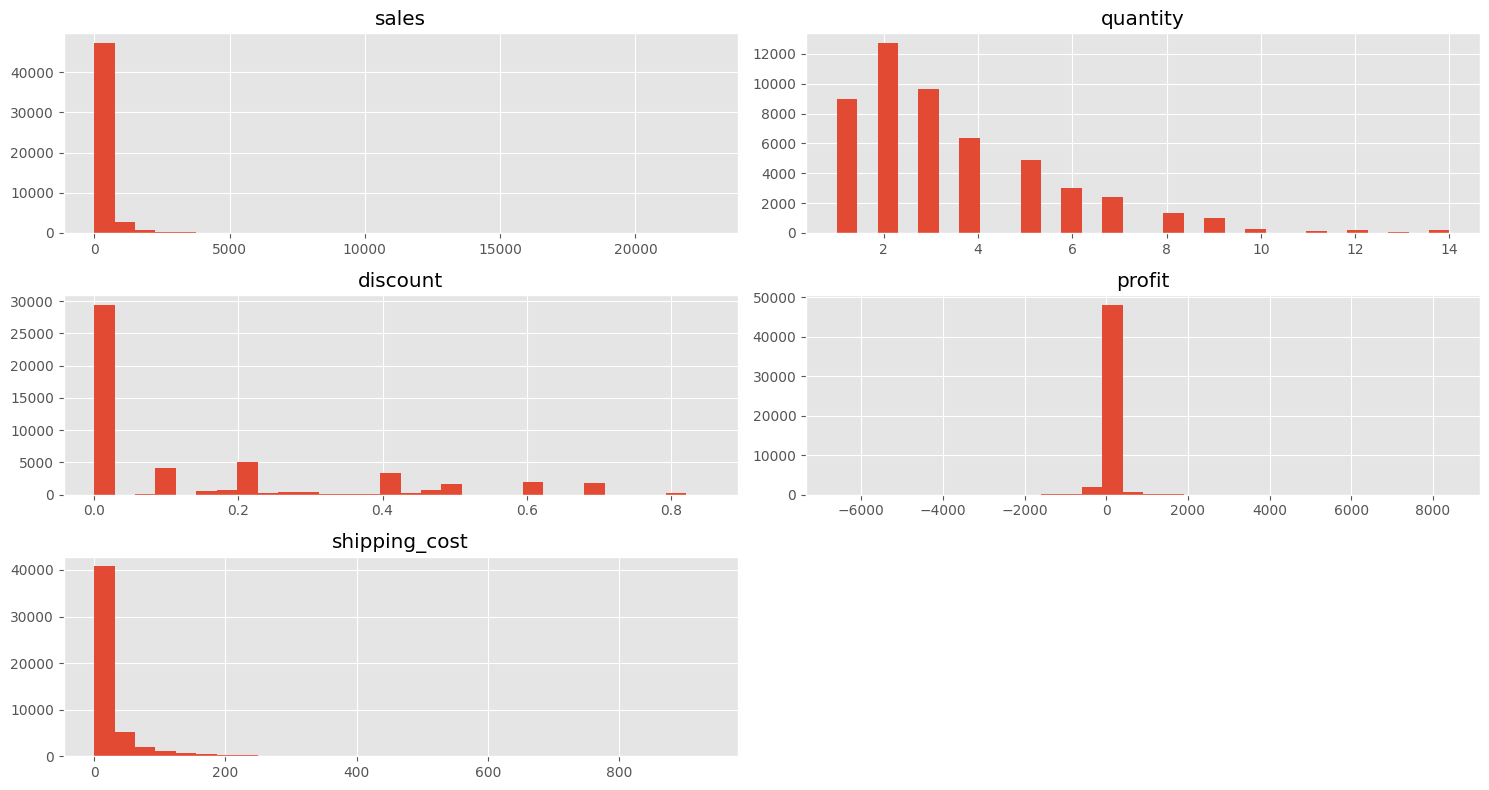

In [ ]:
numeric_cols = ['sales','quantity','discount','profit','shipping_cost']

df[numeric_cols].hist(figsize=(15,8), bins=30)

plt.tight_layout()
plt.show()

In [ ]:
print("Total Sales :", df['sales'].sum())

Total Sales : 12642905.0


In [ ]:
print("Total Profit :", df['profit'].sum())

Total Profit : 1469034.8212799998


In [ ]:
print("Total Quantity :", df['quantity'].sum())

Total Quantity : 178312


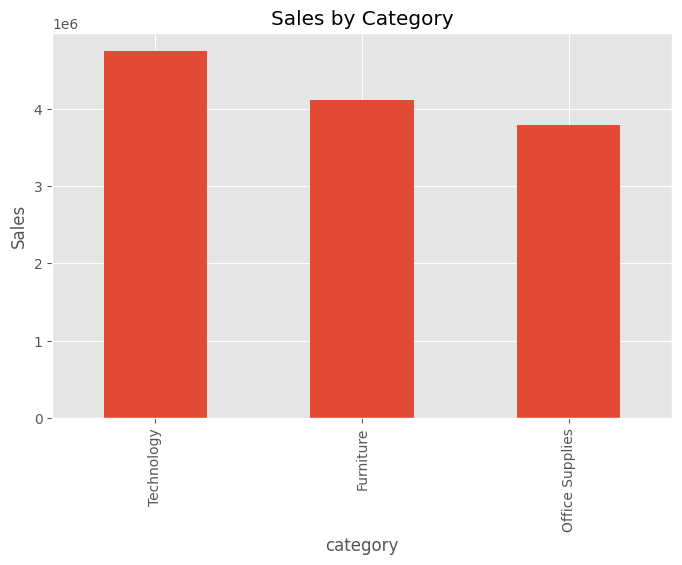

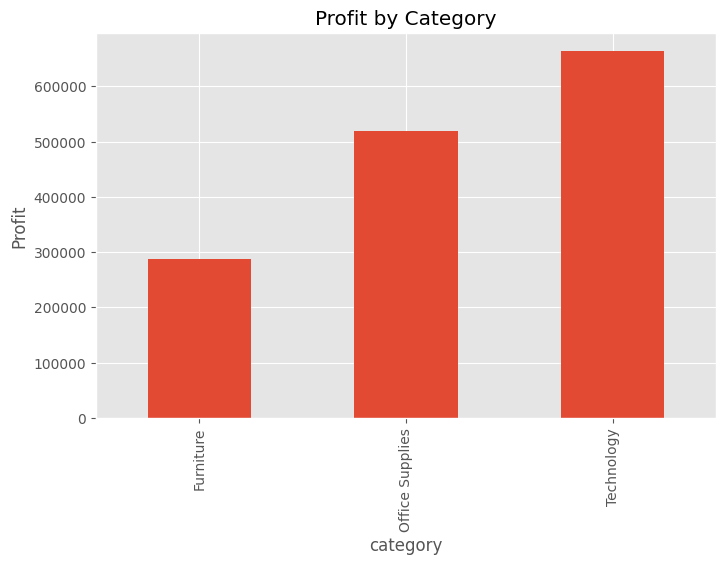

In [ ]:
# Sales berdasarkan Category
sales_category = df.groupby('category')['sales'].sum().sort_values(ascending=False)

plt.figure(figsize=(8,5))
sales_category.plot(kind='bar')

plt.title("Sales by Category")
plt.ylabel("Sales")

plt.show()

# Profit berdasarkan Category
profit_category = df.groupby('category')['profit'].sum().sort_values()

plt.figure(figsize=(8,5))
profit_category.plot(kind='bar')

plt.title("Profit by Category")
plt.ylabel("Profit")

plt.show()

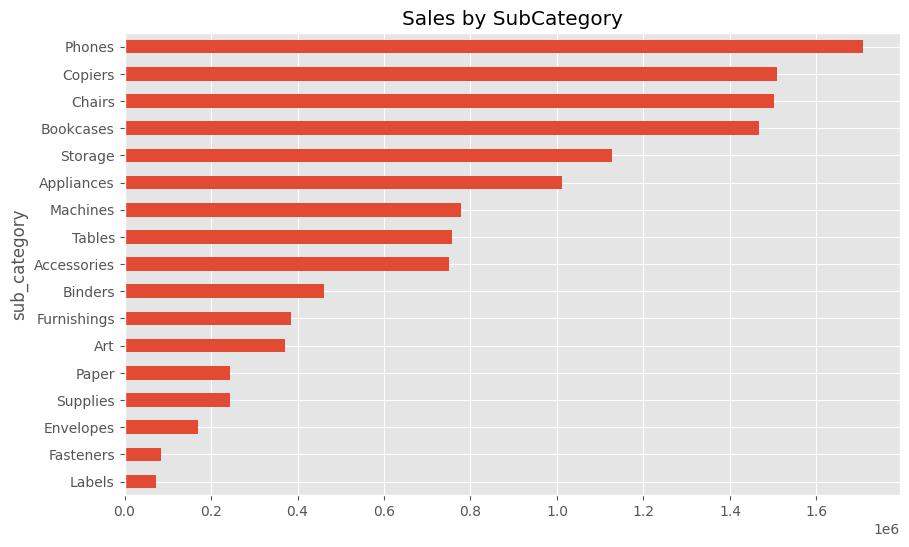

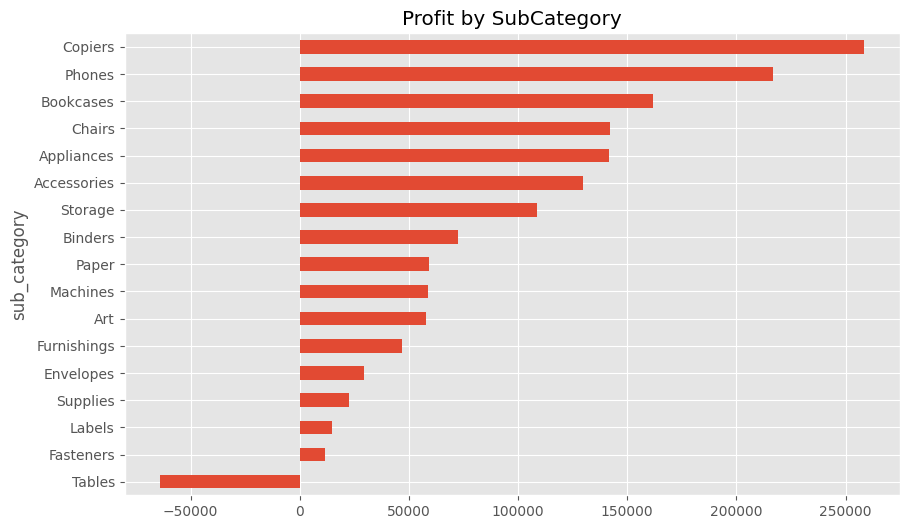

In [ ]:
# Sales berdasarkan SubCategory
sales_sub = df.groupby('sub_category')['sales'].sum().sort_values()

plt.figure(figsize=(10,6))
sales_sub.plot(kind='barh')

plt.title('Sales by SubCategory')
plt.show()

# Profit berdasarkan SubCategory
profit_sub = df.groupby('sub_category')['profit'].sum().sort_values()

plt.figure(figsize=(10,6))
profit_sub.plot(kind='barh')

plt.title('Profit by SubCategory')
plt.show()

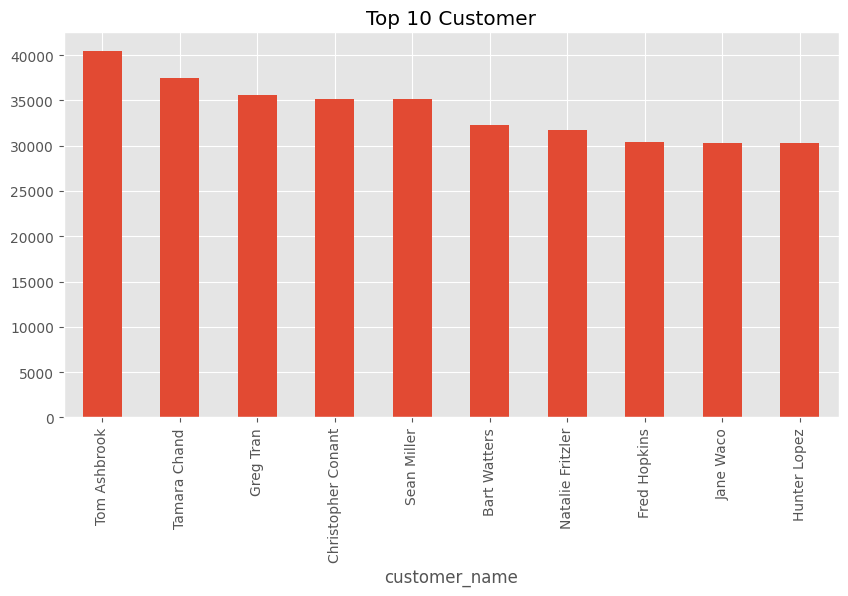

In [ ]:
# Top 10 Cust
top_customer = df.groupby('customer_name')['sales'].sum().sort_values(ascending=False).head(10)

plt.figure(figsize=(10,5))
top_customer.plot(kind='bar')

plt.title("Top 10 Customer")

plt.show()

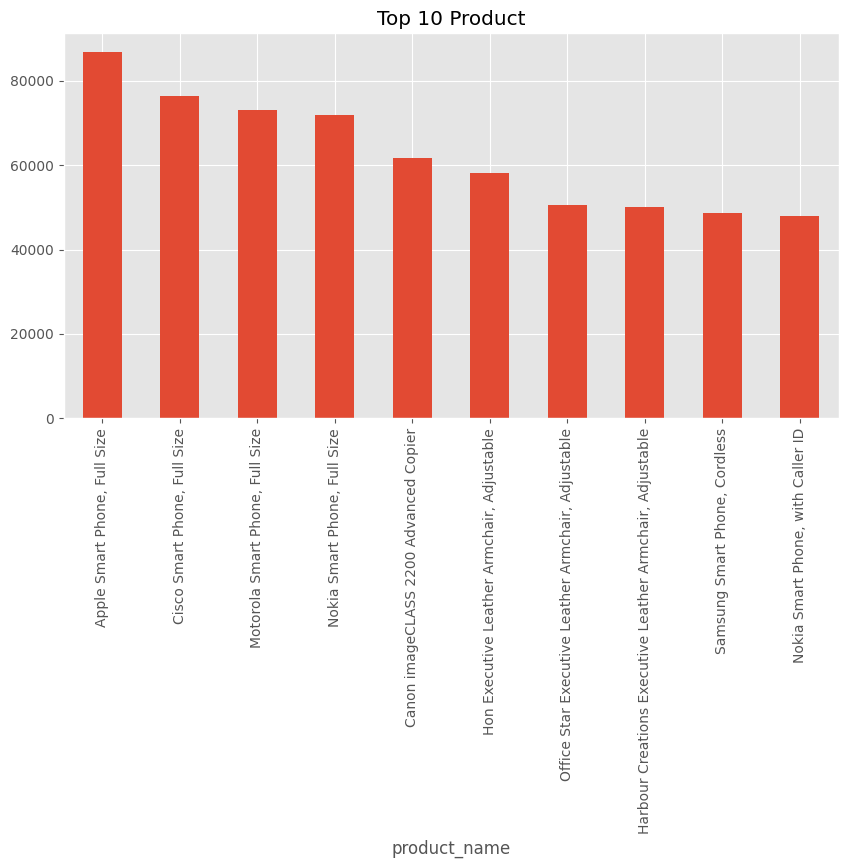

In [ ]:
#Top 10 Product

top_product = df.groupby('product_name')['sales'].sum().sort_values(ascending=False).head(10)

plt.figure(figsize=(10,5))
top_product.plot(kind='bar')

plt.title('Top 10 Product')
plt.show()


Text(0.5, 1.0, 'Sales by Market')

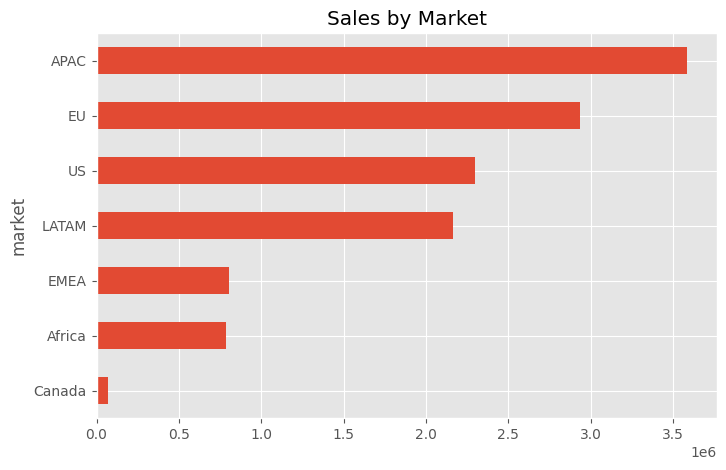

In [ ]:
# Sales berdasarkan Market
market = df.groupby('market')['sales'].sum().sort_values()

plt.figure(figsize=(8,5))
market.plot(kind='barh')

plt.title('Sales by Market')

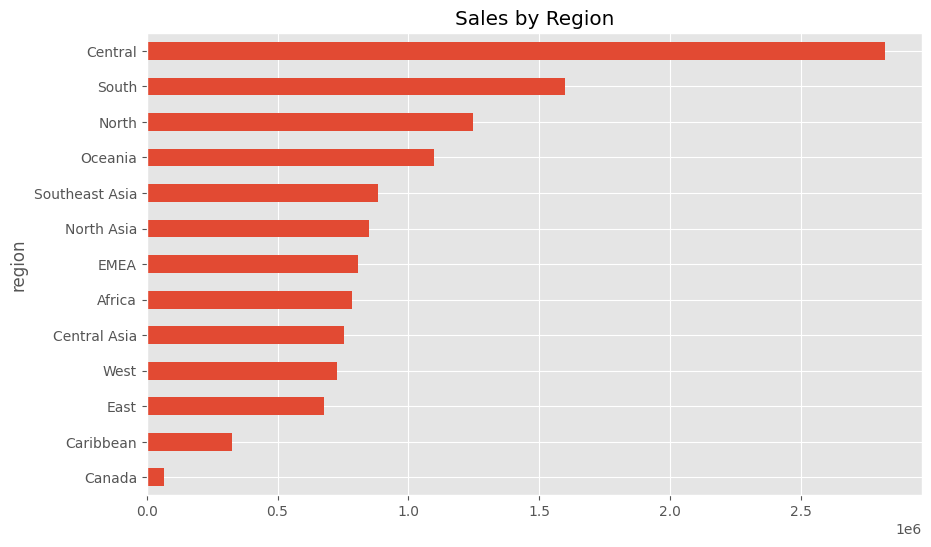

In [ ]:
#Sales berdasarkan region

region = df.groupby('region')['sales'].sum().sort_values()

plt.figure(figsize=(10,6))
region.plot(kind='barh')

plt.title("Sales by Region")
plt.show()

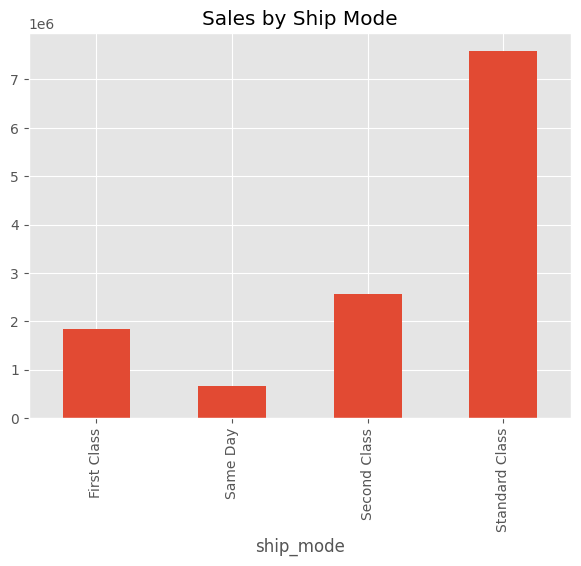

In [ ]:
# Sales berdasarkan ship mode

ship = df.groupby('ship_mode')['sales'].sum()
plt.figure(figsize=(7,5))
ship.plot(kind='bar')

plt.title('Sales by Ship Mode')
plt.show()

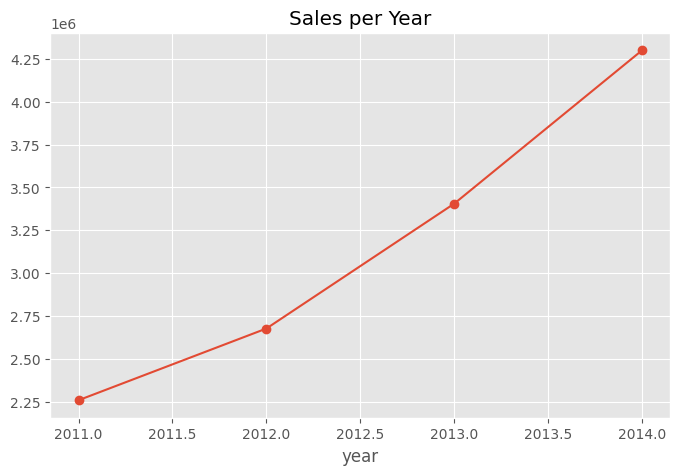

In [ ]:
sales_year = df.groupby('year')['sales'].sum()

plt.figure(figsize=(8,5))
sales_year.plot(marker='o')

plt.title('Sales per Year')
plt.show()

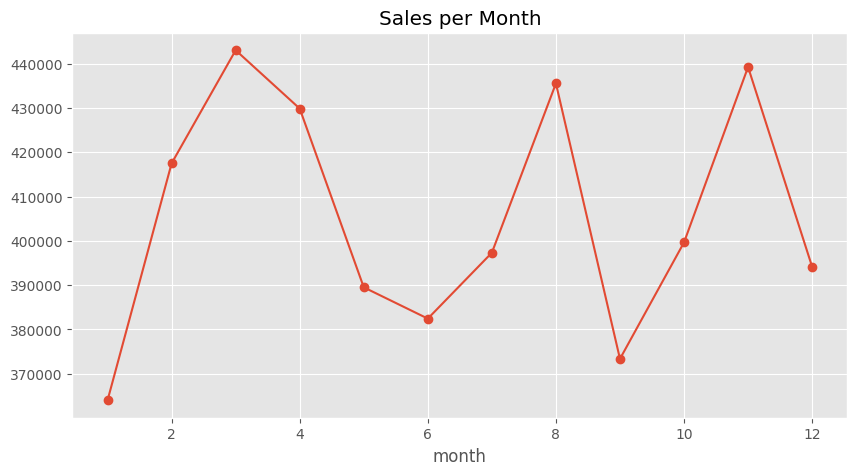

In [ ]:
#Sales per Bulan

df['month'] = df['order_date'].dt.month

sales_month = df.groupby('month')['sales'].sum()
plt.figure(figsize=(10,5))
sales_month.plot(marker='o')

plt.title('Sales per Month')
plt.show()

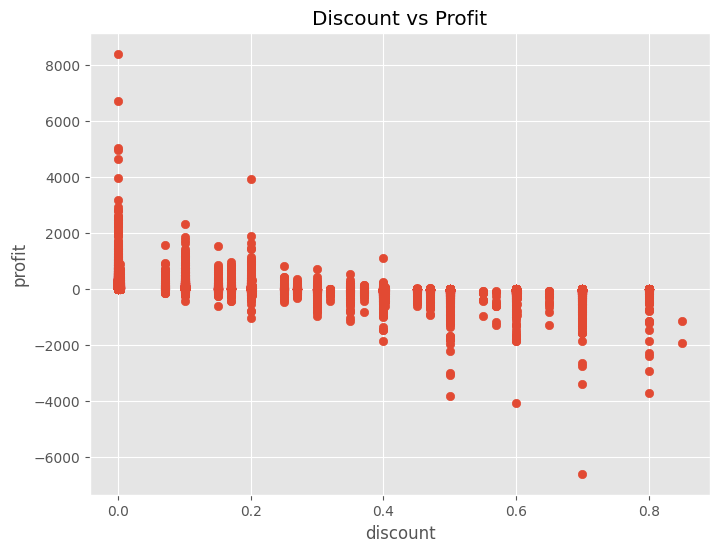

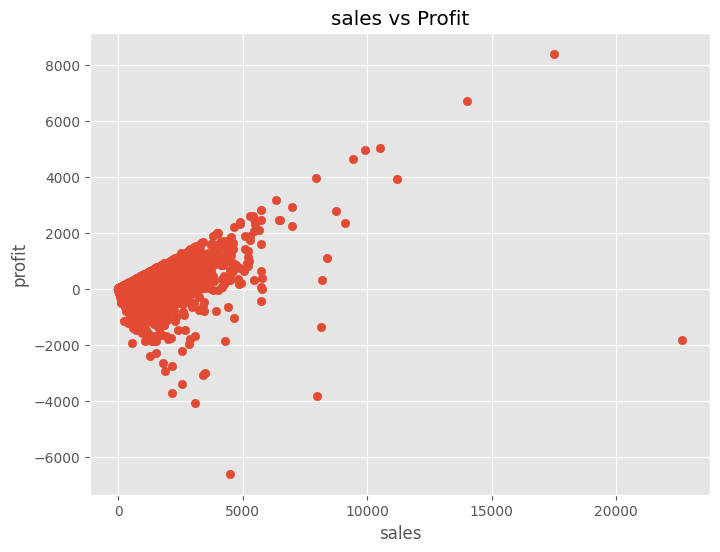

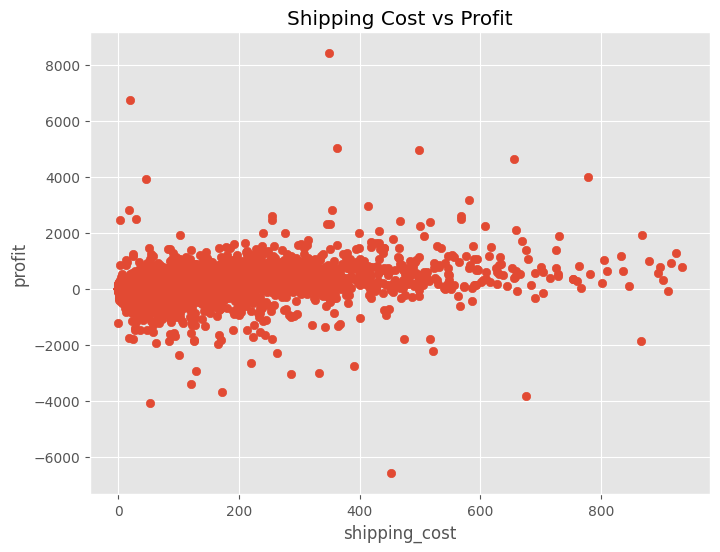

In [ ]:
#Discout vs profit

plt.figure(figsize=(8,6))
plt.scatter(df['discount'], df['profit'])

plt.xlabel('discount')
plt.ylabel('profit')

plt.title('Discount vs Profit')
plt.show()

#sales vs profit

plt.figure(figsize=(8,6))
plt.scatter(df['sales'], df['profit'])

plt.xlabel('sales')
plt.ylabel('profit')

plt.title('sales vs Profit')
plt.show()

#Shipping cost vs profit

plt.figure(figsize=(8,6))
plt.scatter(df['shipping_cost'], df['profit'])

plt.xlabel('shipping_cost')
plt.ylabel('profit')

plt.title('Shipping Cost vs Profit')
plt.show()

In [ ]:
#Correlation

corr = df[['sales',
           'quantity',
           'discount',
           'profit',
           'shipping_cost']].corr()

corr

,sales,quantity,discount,profit,shipping_cost
sales,1.000000,0.313580,-0.086728,0.485944,0.768075
quantity,0.313580,1.000000,-0.019875,0.104743,0.272649
discount,-0.086728,-0.019875,1.000000,-0.316375,-0.079056
profit,0.485944,0.104743,-0.316375,1.000000,0.357033
shipping_cost,0.768075,0.272649,-0.079056,0.357033,1.000000


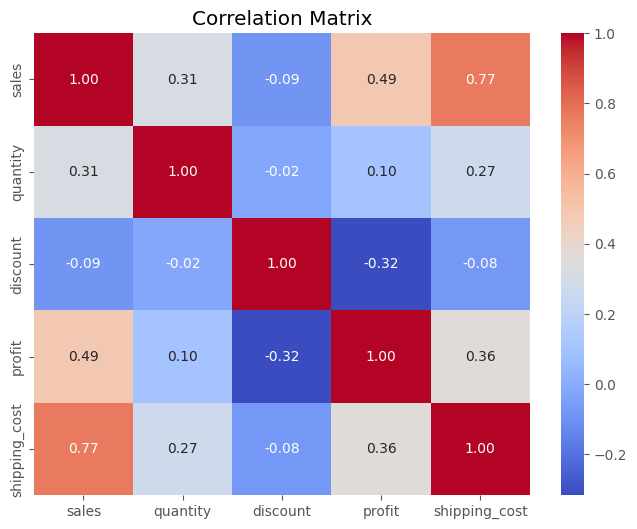

In [ ]:
#Heatmap Korelasi

plt.figure(figsize=(8,6))

sns.heatmap(corr,
            annot=True,
            cmap='coolwarm',
            fmt='.2f')

plt.title("Correlation Matrix")

plt.show()


In [ ]:
df.to_csv('Superstore_Clean.csv', index=False)